# DML, DiD и IPCW из Causalis на органической активации

Сравниваем реальные оцениватели Causalis: `IRM(...).estimate(score="ATTE")`,
`CallawaySantAnnaDID(estimator="dr")` и `IPCW(...).estimate(n_bootstrap=199)`.

Основное сравнение — одна treated-когорта `g=10` и накопленный LTV за шесть
месяцев. Для IPCW рассчитываем SE, p-value и 95% интервалы с bootstrap по
клиентам и полным переобучением моделей весов. Затем проверяем общий estimand
при `H=1` и повторяем сравнение в шести сценариях. Это иллюстрация на одном
фиксированном seed, а не исследование смещения или покрытия интервалов.

[Генератор и подготовка данных](organic_activation.ipynb) ·
[Математическое описание DGP](organic_activation.md) · [API IPCW](ipcw.md).


In [1]:
from pathlib import Path
import sys
import time

repo_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "causalis").is_dir() and (p / "pyproject.toml").is_file()),
    None,
)
if repo_root is not None and str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostClassifier, CatBoostRegressor

from causalis.data_contracts import CausalData, IPCWData, PanelDataDID
from causalis.dgp import generate_organic_activation_data
from causalis.dgp.organic_activation import make_dml_view, make_ipcw_view, summarize_data, validate_data
from causalis.scenarios.unconfoundedness import IRM
from causalis.scenarios.did import CallawaySantAnnaDID

pd.set_option("display.max_columns", 25)
pd.set_option("display.max_rows", 30)
pd.set_option("display.precision", 2)
plt.rcParams.update({"font.size": 10, "figure.figsize": (12, 4)})

from causalis.scenarios.ipcw import (
    IPCW, ipcw_support_table, ipcw_weight_summary_table, run_ipcw_diagnostics,
)


/Users/ioann/.matplotlib is not a writable directory
Matplotlib created a temporary cache directory at /var/folders/q3/_6b29v_d0530shyt9kcy2n1h0000gn/T/matplotlib-58wv29bb because there was an issue with the default path (/Users/ioann/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.
Matplotlib is building the font cache; this may take a moment.


## 1. Конфигурация и одна исходная панель

Treatment поглощающее и начинается в начале месяца. В `baseline` отбор
зависит от наблюдаемых X, календарного периода и tenure. Все клиенты
наблюдаются с момента входа до конца панели; изменение состояния `L`
не зависит от treatment.

`N_CLIENTS=20_000` даёт несколько сотен treated в когорте `G=10`.
Размер можно изменить. Коэффициенты DGP и seed не подбираются по результатам.
`RUN_SCENARIOS=False` позволяет выполнить только основное сравнение.

Основной IPCW использует 199 полных bootstrap-переобучений. В обзоре остальных
сценариев IPCW по умолчанию считается без интервалов
(`IPCW_SCENARIO_BOOTSTRAP_REPLICATIONS=0`); можно включить 199 или больше
реплик и для него. Для более стабильного итогового inference используйте 499+.
В каждой IPCW-модели один поток; параллелизм задаётся bootstrap jobs.


In [2]:
N_CLIENTS = 20_000
N_PERIODS = 24
G = 10
HORIZON = 6
SEED = 42
SCENARIO = "baseline"
RUN_SCENARIOS = True
N_FOLDS = 3
CATBOOST_ITERATIONS = 200
LEARNER_THREADS = 2
PROPENSITY_EPS = 1e-6
CENSORING_EPS = 1e-6
IPCW_BOOTSTRAP_REPLICATIONS = 199
IPCW_SCENARIO_BOOTSTRAP_REPLICATIONS = 0
IPCW_BOOTSTRAP_JOBS = 2
IPCW_LEARNER_THREADS = 1

assert 1 <= G <= 10 and G + HORIZON <= N_PERIODS

df, oracle, metadata = generate_organic_activation_data(
    n_clients=N_CLIENTS, n_periods=N_PERIODS, horizon=HORIZON,
    scenario=SCENARIO, seed=SEED,
)
checks = validate_data(df, oracle, metadata)
diagnostics = summarize_data(df, oracle, metadata)
assert all(value for name, value in checks.items() if not name.startswith("support_"))
display(pd.Series(diagnostics["overview"], name="value").to_frame())
display(diagnostics["control_support"].query("g == @G"))
display(df.head())


,value
scenario,baseline
n_clients,20000
n_rows,389689
never_activated_fraction,0.32
n_main_cohort_treated,5413


,g,t,event_time,n_treated,n_controls,n_censored_controls
54,10,10,0,813,14587,0
55,10,11,1,813,13745,842
56,10,12,2,813,12885,1702
57,10,13,3,813,11982,2605
58,10,14,4,813,11088,3499
59,10,15,5,813,10236,4351


,client_id,period,date,entry_period,tenure_months,n_pre_periods_available,first_activation_period,activation_now,treated,eligible_to_activate,event_time,x_income,x_salary,x_segment,x_digital,x_noise_1,x_noise_2,l_activity_pre,ltv_monthly,ltv_cumulative
0,0,3,2024-04-01,3,0,0,11,False,False,False,-8,115677.67,1,1,0.64,-1.09,0.53,1.93,1156.93,1156.93
1,0,4,2024-05-01,3,1,1,11,False,False,True,-7,115677.67,1,1,0.64,-1.09,0.53,1.26,1068.95,2225.89
2,0,5,2024-06-01,3,2,2,11,False,False,True,-6,115677.67,1,1,0.64,-1.09,0.53,1.14,1193.86,3419.74
3,0,6,2024-07-01,3,3,3,11,False,False,True,-5,115677.67,1,1,0.64,-1.09,0.53,1.59,1373.90,4793.64
4,0,7,2024-08-01,3,4,4,11,False,False,True,-4,115677.67,1,1,0.64,-1.09,0.53,1.92,1542.56,6336.20


## 2. Что сравнивают методы

| Метод | Контроль | Цель за H месяцев | Oracle |
|---|---|---|---|
| DML / IRM ATTE | Не активировался в g; последующая активация разрешена | Начать сейчас против пропустить g, затем естественное поведение | `ATT_defer_natural` |
| Staggered DR DiD | В каждой ячейке g,t остаётся untreated до t | Начать в g против отсутствия активации | `ATT_no_activation` |
| IPCW ATT | Baseline-контроль цензурируется при поздней активации; доступный префикс взвешивается | Начать в g против отсутствия активации весь горизонт | `ATT_no_activation` |

Все три оценки выражены в рублях за один горизонт, но **у DML другой estimand**. DiD и IPCW оценивают один no-activation ATT при разных предпосылках.
Численная разница между оценками сама по себе не является смещением метода.
Каждую оценку сверяем с oracle соответствующей когорты и intervention.

В `H=1` естественная поздняя активация ещё не может повлиять на outcome:
у всех трёх методов общий oracle. Ниже это сравнение выполнено отдельно.


In [3]:
cohort_oracle = oracle["att_by_cohort"].query("g == @G").sort_values("event_time")
display(cohort_oracle)
display(diagnostics["dml_later_activation"].query("g == @G"))
np.testing.assert_array_equal(
    cohort_oracle.loc[cohort_oracle["event_time"].eq(0), "att_no_activation"].to_numpy(),
    cohort_oracle.loc[cohort_oracle["event_time"].eq(0), "att_defer_natural"].to_numpy(),
)


,g,event_time,n_treated,weight,att_no_activation,att_defer_natural,cumulative_no_activation,cumulative_defer_natural
54,10,0,813,0.15,93.92,93.92,93.92,93.92
55,10,1,813,0.15,160.01,152.99,253.93,246.91
56,10,2,813,0.15,207.04,186.66,460.97,433.57
57,10,3,813,0.15,241.01,204.16,701.98,637.73
58,10,4,813,0.15,266.03,209.04,968.01,846.77
59,10,5,813,0.15,284.94,207.05,1252.95,1053.82


,g,n_controls,n_later_activators,fraction_later_activation,n_activations_within_horizon,fraction_activation_within_horizon
9,10,14587,8244,0.57,4351,0.3


## 3. Наблюдаемые признаки

Локальная реализация DiD использует логистическую propensity-модель и линейную
outcome-регрессию. Поэтому преобразуем наблюдаемый доход и добавляем индикаторы
месяца входа: этот базис представляет условное среднее **изменения** месячного
outcome в `baseline` и `latent_level_confounding`. Константы преобразования
берутся из открытой конфигурации DGP; скрытые величины и oracle outcomes
не используются.

DiD получает только статические X и entry. DML дополнительно получает
предрешенческое `L_g`. Шумовые outcome-лаги не включаем в DiD: при отборе по
скрытому уровню они могут нарушить conditional parallel trends.

IPCW получает замороженные `b_*` признаки для baseline assignment и текущее
предрешенческое состояние для censoring из manifests `make_ipcw_view`.
Текущий outcome, будущая активация и oracle не входят в модели весов.


In [4]:
def add_observed_basis(frame, config):
    result = frame.copy()
    result["income_tanh"] = np.tanh(
        (np.log(result["x_income"]) - config["income_log_mean"])
        / config["income_log_std"]
    )
    result["digital_sine"] = np.sin(np.pi * result["x_digital"])
    result["salary_digital"] = result["x_salary"] * result["x_digital"]
    entry_dummies = pd.get_dummies(
        result["entry_period"], prefix="entry", drop_first=True, dtype=float
    )
    result = pd.concat([result, entry_dummies], axis=1)
    static_features = [
        "income_tanh", "x_salary", "x_segment", "x_digital",
        "x_noise_1", "x_noise_2", "digital_sine", "salary_digital",
        *entry_dummies.columns.tolist(),
    ]
    return result, static_features


## 4. DML: IRM с целевым параметром ATTE

Сначала строим baseline risk set. Клиенты с поздней активацией остаются
`d=0`, а `y_ltv_h` включает их фактические outcomes. Для nuisance-моделей
используем CatBoost с фиксированными настройками и cross-fitting с тремя folds.
В baseline-view одна строка на клиента, поэтому folds автоматически разделяют
клиентов. Файлы CatBoost не сохраняются.

Используем явно заданный численный clipping `1e-6`, без удаления наблюдений;
ниже показываем, сколько propensity было изменено. Это настройка оценивателя,
а не скрытая фильтрация генератора.


In [5]:
def fit_dml(panel, design_metadata, g, horizon):
    view = make_dml_view(panel, g=g, horizon=horizon)
    frame, static_features = add_observed_basis(view, design_metadata["config"])
    features = static_features + ["l_activity_pre"]
    data = CausalData.from_df(
        frame, treatment="d", outcome="y_ltv_h",
        confounders=features, user_id="client_id",
    )
    model = IRM(
        data=data,
        ml_g=CatBoostRegressor(
            iterations=CATBOOST_ITERATIONS, depth=5, learning_rate=0.05,
            loss_function="RMSE", l2_leaf_reg=5, random_seed=SEED,
            thread_count=LEARNER_THREADS, allow_writing_files=False, verbose=False,
        ),
        ml_m=CatBoostClassifier(
            iterations=CATBOOST_ITERATIONS, depth=5, learning_rate=0.05,
            loss_function="Logloss", l2_leaf_reg=5, random_seed=SEED,
            thread_count=LEARNER_THREADS, allow_writing_files=False, verbose=False,
        ),
        n_folds=N_FOLDS, n_jobs=1, random_state=SEED,
        overlap_policy="clip", overlap_threshold=PROPENSITY_EPS,
        store_diagnostics=True,
    ).fit()
    estimate = model.estimate(score="ATTE")
    assert model.overlap_n_dropped_ == 0
    return {"view": view, "model": model, "estimate": estimate, "features": features}

started = time.perf_counter()
dml = fit_dml(df, metadata, G, HORIZON)
print(f"DML: {time.perf_counter() - started:.2f} сек.")
display(dml["estimate"].summary())
print("X:", dml["features"])


DML: 1.35 сек.


,value
field,
outcome,y_ltv_h
estimand,ATTE
model,IRM
value,"1177.9785 (ci_abs: 1054.2927, 1301.6644)"
value_relative,"23.2828 (ci_rel: 20.3212, 26.2445)"
alpha,0.0500
p_value,0.0000
is_significant,True
n_treated,813


X: ['income_tanh', 'x_salary', 'x_segment', 'x_digital', 'x_noise_1', 'x_noise_2', 'digital_sine', 'salary_digital', 'entry_1', 'entry_2', 'entry_3', 'entry_4', 'entry_5', 'entry_6', 'entry_7', 'entry_8', 'entry_9', 'l_activity_pre']


## 5. DiD: Callaway–Sant’Anna на месячном LTV

Берём **те же baseline-eligible client_id**, сохраняем периоды `G-1 … G+H-1`
и фактический `treated`. В каждой ячейке локальная модель выбирает
not-yet-treated/never-treated контроль. Поздние активаторы остаются в панели.

Дата преобразуется в явный `Period[M]`, как ожидает контракт `PanelDataDID`.
Из `att_gt` выбираем только когорту G: общий `result.att` и общий event study
смешивают несколько когорт и здесь не являются целевым результатом.

`aggregate("cohort")` возвращает среднее по месячным ATT. При наличии всех H
месяцев умножаем его оценку, SE и границы интервала на H. Штатная агрегация
influence scores учитывает ковариацию между месяцами.


In [6]:
def fit_did(panel, design_metadata, g, horizon):
    risk_view = make_dml_view(panel, g=g, horizon=horizon)
    window = panel.loc[
        panel["client_id"].isin(risk_view["client_id"])
        & panel["period"].between(g - 1, g + horizon - 1)
    ].copy()
    window, features = add_observed_basis(window, design_metadata["config"])
    window["month"] = window["date"].dt.to_period("M")
    data = PanelDataDID(
        df=window, y="ltv_monthly", unit_col="client_id", time_col="month",
        treated_time="treated", covariates=features,
    )
    model = CallawaySantAnnaDID(
        estimator="dr", control_group="not_yet_or_never",
        anticipation=0, base_period="universal", include_pre_periods=False,
        propensity_clip=PROPENSITY_EPS, diagnostic_data=True,
        bootstrap_replications=0, random_state=SEED,
    ).fit(data)
    result = model.estimate()
    g_month = pd.Period(design_metadata["config"]["calendar_start"], freq="M") + g
    target = result.att_gt.loc[result.att_gt["cohort"].eq(g_month)].sort_values("event_time")
    if target["event_time"].tolist() != list(range(horizon)):
        raise RuntimeError("Для целевой когорты доступны не все H месяцев; горизонт не сокращаем.")
    expected_treated = int(risk_view["d"].sum())
    assert target["n_treated"].eq(expected_treated).all()
    cohort = result.aggregate("cohort")
    cohort = cohort.loc[cohort["cohort"].eq(g_month)].iloc[0]
    total = {
        "estimate": horizon * float(cohort["estimate"]),
        "se": horizon * float(cohort["se"]),
        "ci_lower": horizon * float(cohort["ci_lower"]),
        "ci_upper": horizon * float(cohort["ci_upper"]),
    }
    np.testing.assert_allclose(total["estimate"], target["att"].sum())
    return {"model": model, "result": result, "target": target,
            "total": total, "features": features, "g_month": g_month}

started = time.perf_counter()
did = fit_did(df, metadata, G, HORIZON)
print(f"DiD: {time.perf_counter() - started:.2f} сек.")
display(did["target"][["cohort", "time", "event_time", "att", "se",
                        "n_treated", "n_control", "control_weight_ess",
                        "propensity_clip_share", "diagnostic_status"]])
print("X:", did["features"])


DiD: 2.73 сек.


,cohort,time,event_time,att,se,n_treated,n_control,control_weight_ess,propensity_clip_share,diagnostic_status
0,2024-11,2024-11,0,73.29,13.27,813,14587,10918.46,0.0,green
1,2024-11,2024-12,1,164.50,13.91,813,13745,9917.04,0.0,green
2,2024-11,2025-01,2,203.92,14.87,813,12885,8898.31,0.0,green
3,2024-11,2025-02,3,223.08,15.63,813,11982,7936.84,0.0,green
4,2024-11,2025-03,4,244.33,15.60,813,11088,7009.87,0.0,green
5,2024-11,2025-04,5,287.00,15.15,813,10236,6137.55,0.0,green


X: ['income_tanh', 'x_salary', 'x_segment', 'x_digital', 'x_noise_1', 'x_noise_2', 'digital_sine', 'salary_digital', 'entry_1', 'entry_2', 'entry_3', 'entry_4', 'entry_5', 'entry_6', 'entry_7', 'entry_8', 'entry_9']


## 6. IPCW: ATT без последующей активации

Используем тот же baseline risk set, что DML и целевая когорта DiD.
`make_ipcw_view` сохраняет все H строк клиента. Поздняя активация контроля
входит в обучение censoring hazard, но outcome её месяца и последующие
outcomes уже не участвуют в оценке.

На доступных контрольных outcomes вес равен

\[
w_{it}=\frac{\hat e_i}{1-\hat e_i}
       \prod_{s=g+1}^{t}\frac{1}{1-\hat h_{is}}.
\]

В baseline survival равен 1: assignment не входит в произведение повторно.
Веса нормируются отдельно в каждом месяце по Hájek; `estimate.value` уже
суммирует месячные ATT и не требует умножения на H. Обе модели весов — CatBoost
с теми же depth, learning rate и числом итераций, что assignment-модель DML.
Cross-fitting группирует все строки клиента. Clipping assignment симметричен,
а вероятность остаться нецензурированным ограничивается только снизу.

Инференс — **client-refit bootstrap Wald**, условно на исходных client folds.
Каждая реплика переобучает обе модели вероятностей. Месячные, накопленные
и суммарный эффекты используют одни реплики, сохраняя межмесячную ковариацию.
Cross-fitting не делает IPCW doubly robust; bootstrap не устраняет hidden
confounding и ошибки моделей весов. При ошибке bootstrap сохраняем точечную
оценку с явным статусом ошибки inference, без повторного отбора реплик.


In [7]:
def fit_ipcw(panel, design_metadata, g, horizon, *,
             n_bootstrap=IPCW_BOOTSTRAP_REPLICATIONS):
    view = make_ipcw_view(panel, g=g, horizon=horizon)
    data = IPCWData.from_df(view)
    learner_options = dict(
        iterations=CATBOOST_ITERATIONS, depth=5, learning_rate=0.05,
        loss_function="Logloss", l2_leaf_reg=5, random_seed=SEED,
        thread_count=IPCW_LEARNER_THREADS, allow_writing_files=False, verbose=False,
    )
    model = IPCW(
        data=data, ml_m=CatBoostClassifier(**learner_options),
        ml_c=CatBoostClassifier(**learner_options),
        n_folds=N_FOLDS, random_state=SEED, n_jobs=IPCW_BOOTSTRAP_JOBS,
        propensity_clip=PROPENSITY_EPS, censoring_clip=CENSORING_EPS,
        store_diagnostics=True,
    ).fit()
    estimate = model.estimate(alpha=0.05, n_bootstrap=0)
    inference_error = None
    if n_bootstrap:
        try:
            estimate = model.estimate(alpha=0.05, n_bootstrap=n_bootstrap)
        except RuntimeError as exc:
            inference_error = str(exc)
    return {
        "view": view, "model": model, "estimate": estimate,
        "baseline_features": data.baseline_covariates,
        "censoring_features": data.censoring_covariates,
        "requested_bootstrap": n_bootstrap, "inference_error": inference_error,
    }

started = time.perf_counter()
ipcw = fit_ipcw(df, metadata, G, HORIZON)
print(f"IPCW с inference: {time.perf_counter() - started:.2f} сек.")
print("Bootstrap:", ipcw["estimate"].model_options["n_bootstrap"],
      "из запрошенных", ipcw["requested_bootstrap"])
if ipcw["inference_error"] is not None:
    print("IPCW inference недоступен:", ipcw["inference_error"])
display(ipcw["estimate"].summary())
display(ipcw["estimate"].period_effects)
print("Baseline X:", ipcw["baseline_features"])
print("Censoring history:", ipcw["censoring_features"])

dml_treated_ids = dml["view"].loc[dml["view"]["d"].eq(1), "client_id"]
ipcw_treated_ids = ipcw["view"].loc[
    ipcw["view"]["baseline_d"].eq(1), "client_id"
].drop_duplicates()
np.testing.assert_array_equal(np.sort(dml_treated_ids), np.sort(ipcw_treated_ids))
assert ipcw["estimate"].n_treated == int(did["target"]["n_treated"].iloc[0])
assert ipcw["estimate"].value == ipcw["estimate"].cumulative_effects["value"].iloc[-1]


IPCW с inference: 453.49 сек.
Bootstrap: 199 из запрошенных 199


,value
field,
outcome,ltv_monthly
estimand,ATT_no_activation
model,IPCW
value,"1375.2179 (ci_abs: 1249.7533, 1500.6825)"
std_error,64.01
alpha,0.05
p_value,0.0
is_significant,True
trial_id,10


,time,followup_month,value,treatment_mean,control_mean,std_error,ci_lower_absolute,ci_upper_absolute,p_value,is_significant
0,10,0,102.54,757.55,655.01,12.92,77.20,127.87,2.13e-15,True
1,11,1,194.43,950.31,755.89,13.98,167.02,221.83,5.81e-44,True
2,12,2,235.81,1072.48,836.67,14.33,207.71,263.90,8.17e-61,True
3,13,3,252.58,1135.34,882.76,15.26,222.68,282.48,1.45e-61,True
4,14,4,272.20,1142.22,870.03,16.28,240.30,304.09,8.67e-63,True
5,15,5,317.67,1179.49,861.82,14.31,289.62,345.72,3.51e-109,True


Baseline X: ['b_x_income', 'b_x_salary', 'b_x_segment', 'b_x_digital', 'b_x_noise_1', 'b_x_noise_2', 'b_entry_period', 'b_l_activity_pre']
Censoring history: ['x_income', 'x_salary', 'x_segment', 'x_digital', 'x_noise_1', 'x_noise_2', 'entry_period', 'period', 'tenure_months', 'l_activity_pre']


## 7. Результаты относительно собственных oracle

`error_vs_own_oracle = estimate − oracle`. Это ошибка в конкретной симуляции,
не оценка систематического смещения по повторным выборкам.

Для DML/DiD показываем **штатные асимптотические интервалы Causalis**.
Для IPCW — **Wald-интервалы с SE из client-refit bootstrap**.
Столбцы `inference` и `n_bootstrap` указывают тип inference и число реплик.
При нуле реплик или ошибке bootstrap SE, CI и p-value IPCW остаются пустыми. В DiD базис
делает outcome-регрессию правильной в baseline, но cohort propensity не обязана
быть линейно-логистической. При правильной только outcome-регрессии калибровка
такого IF-интервала не гарантирована; для исследования покрытия нужен bootstrap
по клиентам с полным переобучением. По включению oracle в один интервал не
делаем вывод об идентификации.


In [8]:
def comparison_rows(dml_fit, did_fit, scenario_oracle, scenario, g, horizon, ipcw_fit=None):
    truth = scenario_oracle["att_by_cohort"].loc[
        scenario_oracle["att_by_cohort"]["g"].eq(g)
        & scenario_oracle["att_by_cohort"]["event_time"].eq(horizon - 1)
    ].iloc[0]
    rows = []
    if dml_fit is not None:
        est = dml_fit["estimate"]
        rows.append({
            "scenario": scenario, "method": "DML / IRM ATTE", "benchmark": "ATT_defer_natural",
            "estimate": float(est.value), "se": float(dml_fit["model"].se[0]),
            "ci_lower": float(est.ci_lower_absolute), "ci_upper": float(est.ci_upper_absolute),
            "p_value": est.p_value, "oracle": float(truth["cumulative_defer_natural"]),
            "n_treated": int(est.n_treated), "inference": "asymptotic IF",
            "n_bootstrap": 0, "status": "ok",
        })
    if did_fit is not None:
        rows.append({
            "scenario": scenario, "method": "DR DiD", "benchmark": "ATT_no_activation",
            **did_fit["total"], "oracle": float(truth["cumulative_no_activation"]),
            "n_treated": int(did_fit["target"]["n_treated"].iloc[0]),
            "inference": "asymptotic IF", "n_bootstrap": 0, "status": "ok",
        })
    if ipcw_fit is not None:
        est = ipcw_fit["estimate"]
        rows.append({
            "scenario": scenario, "method": "IPCW ATT", "benchmark": "ATT_no_activation",
            "estimate": est.value, "se": est.std_error, "ci_lower": est.ci_lower_absolute,
            "ci_upper": est.ci_upper_absolute, "p_value": est.p_value,
            "oracle": float(truth["cumulative_no_activation"]),
            "n_treated": est.n_treated, "inference": est.model_options["inference"],
            "n_bootstrap": est.model_options["n_bootstrap"],
            "status": "ok" if ipcw_fit["inference_error"] is None
                      else f"inference_failed: {ipcw_fit['inference_error']}",
        })
    for row in rows:
        row["error_vs_own_oracle"] = row["estimate"] - row["oracle"]
    return pd.DataFrame(rows)

comparison = comparison_rows(dml, did, oracle, SCENARIO, G, HORIZON, ipcw_fit=ipcw)
display(comparison)
assert comparison["n_treated"].nunique() == 1


,scenario,method,benchmark,estimate,se,ci_lower,ci_upper,p_value,oracle,n_treated,inference,n_bootstrap,status,error_vs_own_oracle
0,baseline,DML / IRM ATTE,ATT_defer_natural,1177.98,63.11,1054.29,1301.66,0.00e+00,1053.82,813,asymptotic IF,0,ok,124.16
1,baseline,DR DiD,ATT_no_activation,1196.12,67.62,1063.60,1328.65,NaN,1252.95,813,asymptotic IF,0,ok,-56.83
2,baseline,IPCW ATT,ATT_no_activation,1375.22,64.01,1249.75,1500.68,2.24e-102,1252.95,813,client_refit_bootstrap_wald,199,ok,122.27


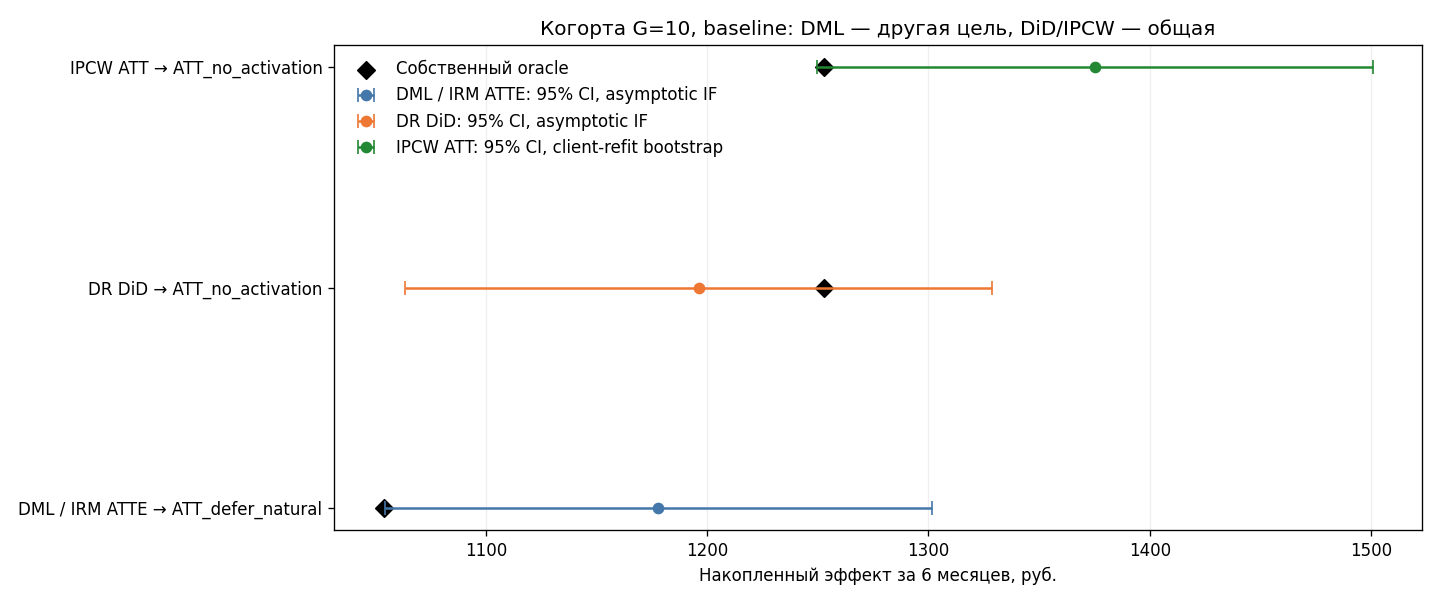

In [9]:
METHOD_COLORS = {
    "DML / IRM ATTE": "#4477AA", "DR DiD": "#EE7733", "IPCW ATT": "#228833",
}
fig, ax = plt.subplots(figsize=(12, 5))
for position, row in comparison.reset_index(drop=True).iterrows():
    color = METHOD_COLORS[row["method"]]
    if pd.notna(row["ci_lower"]) and pd.notna(row["ci_upper"]):
        inference_label = "client-refit bootstrap" if row["method"] == "IPCW ATT" else "asymptotic IF"
        ax.errorbar(
            row["estimate"], position,
            xerr=[[row["estimate"] - row["ci_lower"]],
                  [row["ci_upper"] - row["estimate"]]],
            fmt="o", capsize=4, color=color,
            label=f'{row["method"]}: 95% CI, {inference_label}',
        )
    else:
        ax.scatter(row["estimate"], position, color=color,
                   label=f'{row["method"]}: только точечная оценка')
ax.scatter(comparison["oracle"], np.arange(len(comparison)), marker="D", s=55,
           color="black", label="Собственный oracle")
ax.set_yticks(np.arange(len(comparison)), comparison["method"] + " → " + comparison["benchmark"])
ax.set(xlabel=f"Накопленный эффект за {HORIZON} месяцев, руб.",
       title=f"Когорта G={G}, {SCENARIO}: DML — другая цель, DiD/IPCW — общая")
ax.grid(axis="x", alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
display(fig)
plt.close(fig)


### Динамика DiD/IPCW и тот же cohort-specific oracle

Суммируем только месячные оценки когорты G. Не используем общий event study,
в котором на каждом event time может меняться состав когорт.

IPCW и DiD сверяем с одним no-activation oracle. Полосы IPCW — pointwise
95% CI; накопленные интервалы получены из сумм внутри bootstrap-реплик.


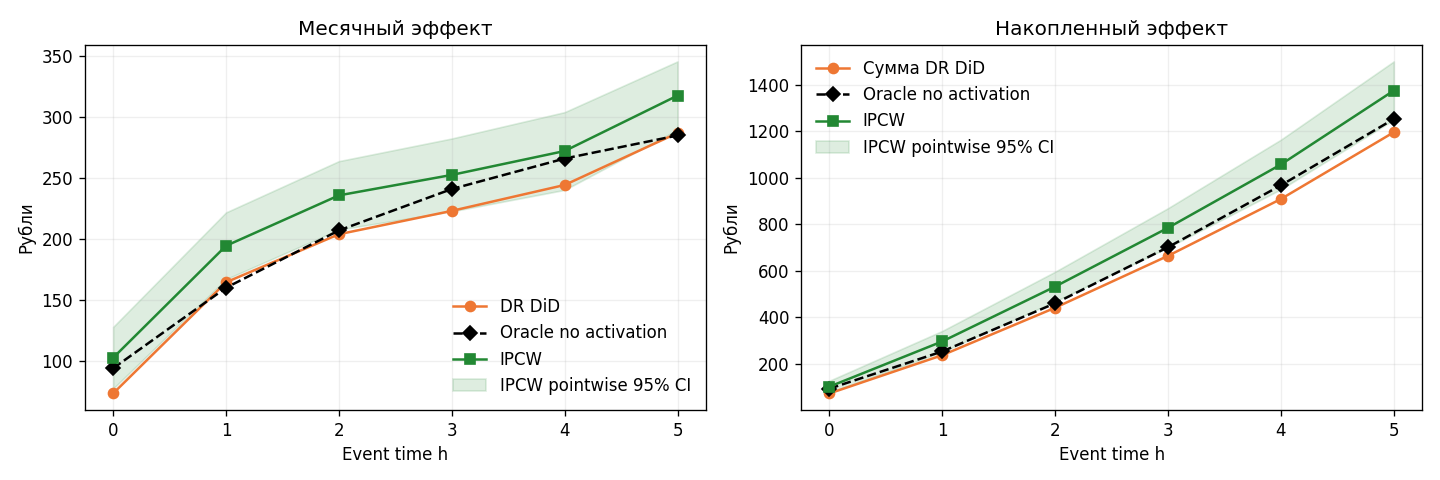

In [10]:
did_curve = did["target"][["event_time", "att"]].merge(
    cohort_oracle[["event_time", "att_no_activation", "cumulative_no_activation"]],
    on="event_time", validate="one_to_one",
)
did_curve["cumulative_estimate"] = did_curve["att"].cumsum()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(did_curve["event_time"], did_curve["att"], "o-", label="DR DiD", color=METHOD_COLORS["DR DiD"])
axes[0].plot(did_curve["event_time"], did_curve["att_no_activation"], "D--", label="Oracle no activation", color="black")
axes[1].plot(did_curve["event_time"], did_curve["cumulative_estimate"], "o-", label="Сумма DR DiD", color=METHOD_COLORS["DR DiD"])
axes[1].plot(did_curve["event_time"], did_curve["cumulative_no_activation"], "D--", label="Oracle no activation", color="black")
for ax, table in zip(axes, [
    ipcw["estimate"].period_effects, ipcw["estimate"].cumulative_effects,
]):
    ax.plot(table["followup_month"], table["value"], "s-", label="IPCW", color="#228833")
    lower = table["ci_lower_absolute"].to_numpy(dtype=float)
    upper = table["ci_upper_absolute"].to_numpy(dtype=float)
    available = np.isfinite(lower) & np.isfinite(upper)
    if available.any():
        ax.fill_between(table["followup_month"].to_numpy(dtype=float), lower, upper,
                        where=available, color="#228833", alpha=0.15,
                        label="IPCW pointwise 95% CI")
    ax.set(xlabel="Event time h", ylabel="Рубли")
    ax.set_xticks(range(HORIZON))
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)
axes[0].set_title("Месячный эффект")
axes[1].set_title("Накопленный эффект")
fig.tight_layout()
display(fig)
plt.close(fig)


### Диагностика overlap и сохранения выборки

Показываем cross-fitted propensity DML, число изменённых propensity и
диагностику каждой целевой DiD-ячейки. Генератор не выполняет trimming.
Слабый overlap может приводить к большой ошибке даже при формальной идентификации.

Для IPCW показываем число цензурированных и доступных контролей, ESS,
survival и обе доли clipping. Цензурирование исключает outcomes по определению
intervention; baseline-клиенты остаются в панели. Малый ESS делает оценку
нестабильной. Диагностики не проверяют отсутствие hidden confounding.


In [11]:
display(pd.Series(dml["model"].m_hat_raw_).quantile(
    [0, .01, .05, .5, .95, .99, 1]
).rename("DML cross-fitted propensity").to_frame())
display(pd.DataFrame([{
    "n_dml_rows": len(dml["view"]),
    "n_dml_dropped": dml["model"].overlap_n_dropped_,
    "n_dml_propensity_clipped": dml["model"].overlap_n_clipped_,
    "did_target_clip_share_max": did["target"]["propensity_clip_share"].max(),
    "did_target_control_ess_min": did["target"]["control_weight_ess"].min(),
    "did_other_skipped_cells": len(did["result"].skipped_cells),
}]))

display(ipcw_support_table(ipcw["estimate"]))
display(ipcw_weight_summary_table(ipcw["estimate"]))
display(run_ipcw_diagnostics(ipcw["estimate"]))


,DML cross-fitted propensity
0.00,6.76e-03
0.01,1.18e-02
0.05,1.77e-02
0.50,4.47e-02
0.95,1.09e-01
0.99,1.56e-01
1.00,4.58e-01


,n_dml_rows,n_dml_dropped,n_dml_propensity_clipped,did_target_clip_share_max,did_target_control_ess_min,did_other_skipped_cells
0,15400,0,0,0.0,6137.55,0


,trial_id,time,followup_month,n_treated,n_control,n_control_at_risk,n_censored,n_control_usable,retention_share,is_supported
0,10,10,0,813,14587,0,0,14587,1.00,True
1,10,11,1,813,14587,14587,842,13745,0.94,True
2,10,12,2,813,14587,13745,860,12885,0.88,True
3,10,13,3,813,14587,12885,903,11982,0.82,True
4,10,14,4,813,14587,11982,894,11088,0.76,True
5,10,15,5,813,14587,11088,852,10236,0.70,True


,trial_id,time,followup_month,n_control_usable,control_weight_sum,control_ess,weight_mean,weight_std,weight_min,weight_max,propensity_clipping_share,censoring_clipping_share,min_survival
0,10,10,0,14587,800.06,10267.91,0.05,0.04,4.62e-03,0.60,0.0,0.0,1.00
1,10,11,1,13745,800.51,9306.45,0.06,0.04,4.67e-03,0.67,0.0,0.0,0.74
2,10,12,2,12885,800.07,8336.70,0.06,0.05,4.74e-03,0.77,0.0,0.0,0.53
3,10,13,3,11982,803.31,7330.96,0.07,0.05,4.83e-03,0.93,0.0,0.0,0.38
4,10,14,4,11088,802.29,6400.82,0.07,0.06,4.93e-03,1.08,0.0,0.0,0.26
5,10,15,5,10236,803.10,5414.79,0.08,0.07,5.04e-03,1.43,0.0,0.0,0.18


,test,flag,value,threshold,message
0,monthly_outcome_support,GREEN,True,all months supported,Every month requires treated clients and contr...
1,min_treated_count,GREEN,813.0,>= 20,Minimum monthly n_treated.
2,min_usable_control_count,GREEN,10236.0,>= 20,Minimum monthly n_control_usable.
3,min_control_retention,GREEN,0.7,>= 0.25,Minimum monthly retention_share.
4,finite_control_weights,GREEN,True,finite and > 0,Usable control outcomes require finite positiv...
5,min_control_ess,GREEN,5414.79,>= 20,Minimum monthly effective control sample size ...
6,baseline_propensity_clipping,GREEN,0.0,<= 0.05,Clipping controls numerical instability but ma...
7,censoring_clipping,GREEN,0.0,<= 0.05,Clipping controls numerical instability but ma...


## 8. H=1: общий estimand для прямого сравнения

В месяце G контроль ещё не мог получить outcome от **последующей** активации.
Поэтому у всех трёх методов общий oracle. Переобучаем DML на одномесячном outcome;
для DiD используем уже рассчитанную ячейку `ATT(G,G)` той же панели.

Для IPCW берём первую строку `period_effects` вместе с bootstrap SE и CI:
survival в baseline равен 1, и эта оценка совпадает с H=1 IPCW на тех же
folds и bootstrap draws. Дополнительное bootstrap-переобучение не требуется.


In [12]:
dml_h1 = fit_dml(df, metadata, G, horizon=1)
first_cell = did["target"].loc[did["target"]["event_time"].eq(0)].iloc[0]
shared_oracle = float(cohort_oracle.iloc[0]["att_no_activation"])
assert shared_oracle == float(cohort_oracle.iloc[0]["att_defer_natural"])
ipcw_first = ipcw["estimate"].period_effects.loc[
    ipcw["estimate"].period_effects["followup_month"].eq(0)
].iloc[0]
common_target = pd.DataFrame([
    {"method": "DML / IRM ATTE", "horizon": 1, "estimate": dml_h1["estimate"].value,
     "se": float(dml_h1["model"].se[0]),
     "ci_lower": dml_h1["estimate"].ci_lower_absolute,
     "ci_upper": dml_h1["estimate"].ci_upper_absolute,
     "inference": "asymptotic IF", "n_bootstrap": 0},
    {"method": "DR DiD", "horizon": 1, "estimate": float(first_cell["att"]),
     "se": float(first_cell["se"]), "ci_lower": float(first_cell["ci_lower"]),
     "ci_upper": float(first_cell["ci_upper"]), "inference": "asymptotic IF", "n_bootstrap": 0},
    {"method": "IPCW ATT", "horizon": 1, "estimate": float(ipcw_first["value"]),
     "se": ipcw_first["std_error"], "ci_lower": ipcw_first["ci_lower_absolute"],
     "ci_upper": ipcw_first["ci_upper_absolute"],
     "inference": ipcw["estimate"].model_options["inference"],
     "n_bootstrap": ipcw["estimate"].model_options["n_bootstrap"]},
])
common_target["shared_oracle"] = shared_oracle
common_target["error_vs_oracle"] = common_target["estimate"] - common_target["shared_oracle"]
display(common_target)


,method,horizon,estimate,se,ci_lower,ci_upper,inference,n_bootstrap,shared_oracle,error_vs_oracle
0,DML / IRM ATTE,1,103.35,12.91,78.04,128.66,asymptotic IF,0,93.92,9.43
1,DR DiD,1,73.29,13.27,47.28,99.31,asymptotic IF,0,93.92,-20.62
2,IPCW ATT,1,102.54,12.92,77.20,127.87,client_refit_bootstrap_wald,199,93.92,8.62


## 9. Шесть сценариев: одинаковые nuisance-настройки оценивателей

| Сценарий | DiD с выбранным статическим conditioning set | DML с L_g |
|---|---|---|
| baseline | Идентификация no-activation ATT | Идентификация defer-natural ATT |
| latent_level_confounding | Постоянный месячный U сокращается | Скрытый уровень нарушает unconfoundedness |
| observed_timevarying_confounding | Нет гарантии parallel trends | Наблюдаемое Markov-состояние достаточно для baseline exchangeability |
| hidden_timevarying_confounding | Нет гарантии | Нет гарантии |
| null_effect | Истинный эффект ноль | Истинный эффект ноль |
| weak_overlap | Формальная идентификация; нестабильность возможна | То же |

Каждый вызов создаёт одну панель; параметры, seed и настройки моделей одинаковы.
Панели разных сценариев не накапливаются в памяти. Если оценка не поддержана,
таблица сохраняет строку с причиной, без изменения seed или сокращения горизонта.

В каждом сценарии меняется состав treated и может измениться сам oracle ATT.
Сравниваем ошибки относительно **собственной** истины, а не сырые оценки между
сценариями. Одна реализация не устанавливает асимптотические свойства метода.

IPCW идентифицирует no-activation ATT в `baseline` и
`observed_timevarying_confounding` при наблюдаемой предрешенческой истории.
Скрытый постоянный уровень нарушает baseline exchangeability; скрытое
меняющееся состояние — sequential exchangeability. В `weak_overlap` важен ESS.

Основная IPCW-строка использует `IPCW_BOOTSTRAP_REPLICATIONS`. Остальные
сценарии — `IPCW_SCENARIO_BOOTSTRAP_REPLICATIONS` (по умолчанию 0).
Обзор сравнивает точечные оценки: отсутствие inference явно видно в таблице
и не заменяется нулевыми SE/интервалами. Успешные методы сохраняются даже
при недоступном fit или inference другого метода.


In [13]:
scenario_results = comparison.copy()
scenario_diagnostics = []

if RUN_SCENARIOS:
    parts = [comparison]
    for scenario_name in metadata["model_features"]:
        if scenario_name == SCENARIO:
            continue
        started = time.perf_counter()
        scenario_df, scenario_oracle, scenario_metadata = generate_organic_activation_data(
            n_clients=N_CLIENTS, n_periods=N_PERIODS, horizon=HORIZON,
            scenario=scenario_name, seed=SEED,
        )
        scenario_fits = {}
        failures = []
        for method_name, fit_function in [("DML / IRM ATTE", fit_dml), ("DR DiD", fit_did), ("IPCW ATT", fit_ipcw)]:
            try:
                scenario_fits[method_name] = fit_function(
                    scenario_df, scenario_metadata, G, HORIZON,
                    **({"n_bootstrap": IPCW_SCENARIO_BOOTSTRAP_REPLICATIONS}
                       if method_name == "IPCW ATT" else {})
                )
            except (ValueError, RuntimeError) as exc:
                failures.append({"scenario": scenario_name, "method": method_name,
                                 "status": f"unsupported: {exc}"})

        successful = comparison_rows(
            scenario_fits.get("DML / IRM ATTE"), scenario_fits.get("DR DiD"),
            scenario_oracle, scenario_name, G, HORIZON, ipcw_fit=scenario_fits.get("IPCW ATT"),
        )
        if failures:
            truth = scenario_oracle["att_by_cohort"].loc[
                scenario_oracle["att_by_cohort"]["g"].eq(G)
                & scenario_oracle["att_by_cohort"]["event_time"].eq(HORIZON - 1)
            ].iloc[0]
            for failure in failures:
                defer = failure["method"] == "DML / IRM ATTE"
                failure.update(
                    benchmark="ATT_defer_natural" if defer else "ATT_no_activation",
                    estimate=np.nan,
                    oracle=float(truth["cumulative_defer_natural" if defer else "cumulative_no_activation"]),
                    error_vs_own_oracle=np.nan, inference="unavailable", n_bootstrap=0,
                )
        parts.append(pd.concat([successful, pd.DataFrame(failures)], ignore_index=True))

        if "DML / IRM ATTE" in scenario_fits:
            fitted_dml = scenario_fits["DML / IRM ATTE"]["model"]
            scenario_diagnostics.append({
                "scenario": scenario_name, "method": "DML / IRM ATTE",
                "clipped_propensity": fitted_dml.overlap_n_clipped_,
                "dropped_rows": fitted_dml.overlap_n_dropped_,
            })
            del fitted_dml
        if "DR DiD" in scenario_fits:
            target = scenario_fits["DR DiD"]["target"]
            scenario_diagnostics.append({
                "scenario": scenario_name, "method": "DR DiD",
                "max_clip_share": target["propensity_clip_share"].max(),
                "min_control_ess": target["control_weight_ess"].min(),
                "diagnostic_flags": "; ".join(sorted(set(target["diagnostic_flags"].astype(str)))),
            })
            del target
        if "IPCW ATT" in scenario_fits:
            weight_summary = ipcw_weight_summary_table(scenario_fits["IPCW ATT"]["estimate"])
            report = run_ipcw_diagnostics(scenario_fits["IPCW ATT"]["estimate"])
            scenario_diagnostics.append({
                "scenario": scenario_name, "method": "IPCW ATT",
                "max_clip_share": weight_summary["propensity_clipping_share"].max(),
                "max_censoring_clip_share": weight_summary["censoring_clipping_share"].max(),
                "min_control_ess": weight_summary["control_ess"].min(),
                "min_survival": weight_summary["min_survival"].min(),
                "n_bootstrap": scenario_fits["IPCW ATT"]["estimate"].model_options["n_bootstrap"],
                "diagnostic_flags": "; ".join(
                    report.loc[report["flag"].ne("GREEN"), "test"] + ":" +
                    report.loc[report["flag"].ne("GREEN"), "flag"]
                ),
            })
            del weight_summary, report
        inference_failures = sum(
            fit.get("inference_error") is not None for fit in scenario_fits.values()
        )
        print(f"{scenario_name}: {time.perf_counter() - started:.2f} сек.; "
              f"недоступных fit: {len(failures)}, ошибок inference: {inference_failures}")
        del scenario_df, scenario_oracle, scenario_metadata, scenario_fits
    scenario_results = pd.concat(parts, ignore_index=True)

display(scenario_results[["scenario", "method", "benchmark", "estimate", "oracle",
                          "error_vs_own_oracle", "inference", "n_bootstrap", "status"]])


latent_level_confounding: 7.92 сек.; недоступных fit: 0, ошибок inference: 0
observed_timevarying_confounding: 7.46 сек.; недоступных fit: 0, ошибок inference: 0
hidden_timevarying_confounding: 7.65 сек.; недоступных fit: 0, ошибок inference: 0
null_effect: 8.24 сек.; недоступных fit: 0, ошибок inference: 0
weak_overlap: 6.77 сек.; недоступных fit: 0, ошибок inference: 0


,scenario,method,benchmark,estimate,oracle,error_vs_own_oracle,inference,n_bootstrap,status
0,baseline,DML / IRM ATTE,ATT_defer_natural,1177.98,1053.82,124.16,asymptotic IF,0,ok
1,baseline,DR DiD,ATT_no_activation,1196.12,1252.95,-56.83,asymptotic IF,0,ok
2,baseline,IPCW ATT,ATT_no_activation,1375.22,1252.95,122.27,client_refit_bootstrap_wald,199,ok
3,latent_level_confounding,DML / IRM ATTE,ATT_defer_natural,2159.45,974.62,1184.83,asymptotic IF,0,ok
4,latent_level_confounding,DR DiD,ATT_no_activation,1180.69,1241.99,-61.31,asymptotic IF,0,ok
5,latent_level_confounding,IPCW ATT,ATT_no_activation,2527.53,1241.99,1285.54,none,0,ok
6,observed_timevarying_confounding,DML / IRM ATTE,ATT_defer_natural,1026.59,937.75,88.84,asymptotic IF,0,ok
7,observed_timevarying_confounding,DR DiD,ATT_no_activation,1184.45,1257.11,-72.66,asymptotic IF,0,ok
8,observed_timevarying_confounding,IPCW ATT,ATT_no_activation,1345.17,1257.11,88.06,none,0,ok
9,hidden_timevarying_confounding,DML / IRM ATTE,ATT_defer_natural,1510.49,974.26,536.23,asymptotic IF,0,ok


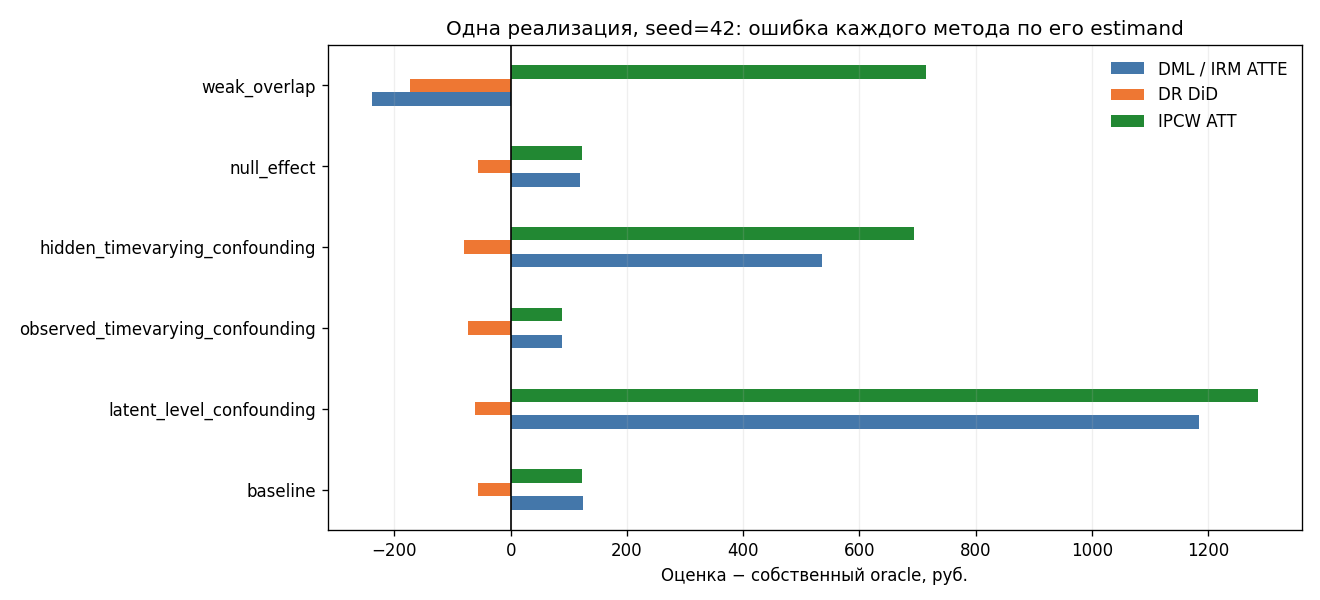

,scenario,method,clipped_propensity,dropped_rows,max_clip_share,min_control_ess,diagnostic_flags,max_censoring_clip_share,min_survival,n_bootstrap
0,latent_level_confounding,DML / IRM ATTE,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
1,latent_level_confounding,DR DiD,NaN,NaN,0.00,7117.64,,NaN,NaN,NaN
2,latent_level_confounding,IPCW ATT,NaN,NaN,0.00,6412.16,,0.0,0.29,0.0
3,observed_timevarying_confounding,DML / IRM ATTE,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
4,observed_timevarying_confounding,DR DiD,NaN,NaN,0.00,2826.56,,NaN,NaN,NaN
5,observed_timevarying_confounding,IPCW ATT,NaN,NaN,0.00,816.91,,0.0,0.03,0.0
6,hidden_timevarying_confounding,DML / IRM ATTE,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
7,hidden_timevarying_confounding,DR DiD,NaN,NaN,0.00,5254.32,,NaN,NaN,NaN
8,hidden_timevarying_confounding,IPCW ATT,NaN,NaN,0.00,4829.83,,0.0,0.21,0.0
9,null_effect,DML / IRM ATTE,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
error_table = scenario_results.pivot(
    index="scenario", columns="method", values="error_vs_own_oracle"
).reindex(
    index=list(metadata["model_features"]) if RUN_SCENARIOS else [SCENARIO],
    columns=list(METHOD_COLORS),
)
ax = error_table.plot.barh(figsize=(11, 5), color=[METHOD_COLORS[name] for name in error_table.columns])
ax.axvline(0, color="black", linewidth=1)
ax.set(xlabel="Оценка − собственный oracle, руб.", ylabel="",
       title=f"Одна реализация, seed={SEED}: ошибка каждого метода по его estimand")
ax.grid(axis="x", alpha=0.2)
ax.legend(frameon=False)
fig = ax.get_figure()
fig.tight_layout()
display(fig)
plt.close(fig)

if scenario_diagnostics:
    display(pd.DataFrame(scenario_diagnostics))


## Как читать сравнение

- В `baseline` сравнивайте каждую оценку с её oracle. При H>1 часть разницы
  между DML и DiD/IPCW обусловлена разными intervention, а не ошибкой оценивания.
- В `H=1` oracle общий для трёх методов: здесь результаты относятся к одной причинной цели.
- `latent_level_confounding` отделяет robustness месячного DiD к постоянному
  скрытому уровню от требования baseline exchangeability для DML/IPCW.
- Наблюдаемое time-varying состояние входит в DML, но не восстанавливает
  автоматически parallel trends для обычного DiD.
- Ни один из этих наборов признаков не устраняет скрытый меняющийся confounding.
- Для вывода о смещении и RMSE повторите симуляцию на заранее заданном наборе
  seeds; сохраняйте ошибки относительно oracle каждой сгенерированной выборки
  и все неуспешные оценки. Близость одного результата к oracle не доказывает
  идентификацию, а выход за штатный интервал не опровергает её.

В памяти остаются `df`, `oracle`, `metadata`, модели `dml` / `did` / `ipcw`, таблицы
`comparison`, `common_target`, `did_curve` и `scenario_results`.

[Callaway–Sant’Anna](https://arxiv.org/abs/1803.09015) ·
[Double/debiased machine learning](https://arxiv.org/abs/1608.00060).

DiD и IPCW оценивают один no-activation ATT. IPCW использует текущую
предрешенческую историю в censoring-модели. Его bootstrap учитывает
переобучение весов, но не гарантирует корректный inference для произвольного
ML. Низкий ESS и большие веса делают оценку нестабильной; clipping может
вносить смещение. IPCW в обзоре остальных сценариев по умолчанию point-only.

[Описание IPCW и его inference](ipcw.md).
